In [ ]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn joblib

In [ ]:
from google.colab import files

uploaded = files.upload()
csv_file = next(iter(uploaded))

print("Uploaded file:", csv_file)

Saving Friday-WorkingHours-Morning.pcap_ISCX.csv to Friday-WorkingHours-Morning.pcap_ISCX.csv
Uploaded file: Friday-WorkingHours-Morning.pcap_ISCX.csv


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv(csv_file, low_memory=False)

# Column name-er extra spaces remove
df.columns = df.columns.str.strip()

# Label column check
label_col = next(
    (c for c in df.columns if c.lower() == "label"),
    None
)

if label_col is None:
    raise ValueError("CSV-te Label column paoa jayni.")

print("Dataset shape:", df.shape)
print("\nAvailable labels:")
print(df[label_col].value_counts().head(15))

# Label-ke binary class-e convert
df["target"] = (
    df[label_col].astype(str).str.strip().str.upper()
    .ne("BENIGN").astype(int)
)

# Original label and possible identifier column bad
X = df.drop(
    columns=[label_col, "target"],
    errors="ignore"
)

# Numeric features only
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)

# Missing value handle
X = X.fillna(0)

# Model training-er jonno manageable subset
data = X.copy()
data["target"] = df["target"].values
data = data.sample(
    n=min(50000, len(data)),
    random_state=42
)

X = data.drop(columns=["target"])
y = data["target"]

print("\nRows used:", len(data))
print("Normal traffic:", (y == 0).sum())
print("Attack traffic:", (y == 1).sum())

Dataset shape: (191033, 79)

Available labels:
Label
BENIGN    189067
Bot         1966
Name: count, dtype: int64

Rows used: 50000
Normal traffic: 49506
Attack traffic: 494


Accuracy: 0.9992

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00      9901
      Attack       1.00      0.92      0.96        99

    accuracy                           1.00     10000
   macro avg       1.00      0.96      0.98     10000
weighted avg       1.00      1.00      1.00     10000



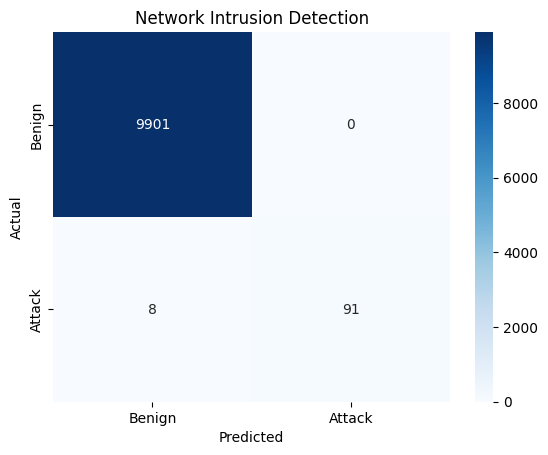

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

if y.nunique() < 2:
    raise ValueError(
        "Dataset-e normal o attack du-dhoroner row dorkar."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Accuracy:", round(
    accuracy_score(y_test, predictions), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Benign", "Attack"],
    zero_division=0
))

cm = confusion_matrix(y_test, predictions)

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Benign", "Attack"],
    yticklabels=["Benign", "Attack"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Network Intrusion Detection")
plt.show()

In [ ]:
os.makedirs("artifacts", exist_ok=True)

joblib.dump(model, "artifacts/intrusion_model.joblib")
joblib.dump(list(X.columns), "artifacts/feature_names.joblib")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
sample = X_test.iloc[[0]]
result = model.predict(sample)[0]
probability = model.predict_proba(sample)[0]

print("Prediction:", "ATTACK" if result == 1 else "BENIGN")
print("Benign probability:", round(probability[0] * 100, 2), "%")
print("Attack probability:", round(probability[1] * 100, 2), "%")

Prediction: BENIGN
Benign probability: 100.0 %
Attack probability: 0.0 %


In [ ]:
from google.colab import files

files.download("artifacts/intrusion_model.joblib")
files.download("artifacts/feature_names.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["BENIGN", "ATTACK"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.9992

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00      9901
      ATTACK       1.00      0.92      0.96        99

    accuracy                           1.00     10000
   macro avg       1.00      0.96      0.98     10000
weighted avg       1.00      1.00      1.00     10000


Confusion Matrix:
[[9901    0]
 [   8   91]]
